# Bank Transaction Clustering

This notebook groups bank transactions into clusters with **K-Means**. It covers exploratory data analysis, data cleaning and preprocessing, model building (elbow method, silhouette score, and a PCA visualization), and cluster interpretation. The cluster labels are exported as the `Target` column and used by the classification notebook (`02_classification.ipynb`).

## Dataset Information

This dataset gives an in-depth view of transaction behavior and financial activity patterns, which makes it well suited for exploring **fraud detection** and **anomaly identification**. It contains **2,512 transaction samples** covering transaction attributes, customer demographics, and usage patterns.

Each record gives a comprehensive view of transaction behavior, enabling analysis for **financial security** and the development of predictive models.

### Key Features

- **`TransactionID`**: Unique alphanumeric identifier for each transaction.
- **`AccountID`**: Unique ID for each account; an account can have multiple transactions.
- **`TransactionAmount`**: Transaction value in currency, ranging from small expenses to large purchases.
- **`TransactionDate`**: Date and time the transaction took place.
- **`TransactionType`**: Transaction type, either `'Credit'` or `'Debit'`.
- **`Location`**: Geographic location of the transaction (US city name).
- **`DeviceID`**: ID of the device used in the transaction.
- **`IP Address`**: IPv4 address used during the transaction; it may change across several accounts.
- **`MerchantID`**: Unique merchant ID, indicating main merchants and anomalous transactions.
- **`AccountBalance`**: Account balance after the transaction.
- **`PreviousTransactionDate`**: Date of the account's previous transaction, useful for computing transaction frequency.
- **`Channel`**: Transaction channel such as `Online`, `ATM`, or `Branch`.
- **`CustomerAge`**: Age of the account holder.
- **`CustomerOccupation`**: Occupation of the user, such as `Doctor`, `Engineer`, `Student`, or `Retired`.
- **`TransactionDuration`**: Duration of the transaction (in seconds).
- **`LoginAttempts`**: Number of login attempts before the transaction; a high number can indicate an anomaly.

## 1. Import Libraries

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

## 2. Load Dataset

The data is read directly from a published Google Sheets CSV. See the project README for the data source and references.

In [2]:
# Load the dataset from a published Google Sheets CSV
url = 'https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?output=csv'
df = pd.read_csv(url)

In [3]:
# Show the first 5 rows
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [4]:
# Show column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [5]:
# Descriptive statistics
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


### Exploratory Data Analysis (EDA)

Correlation heatmap, distributions of numeric and categorical features, and transaction amount by occupation.

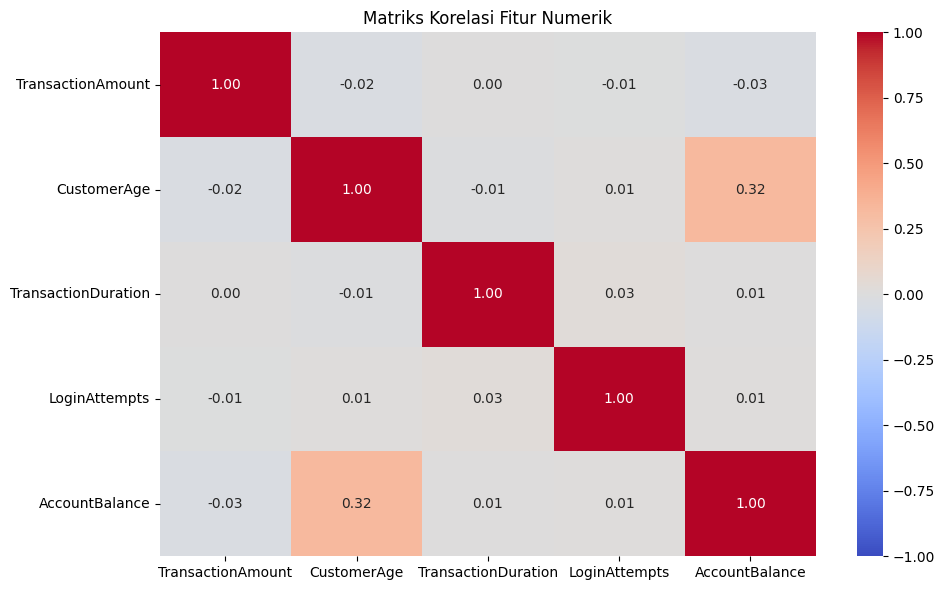

In [6]:
# Correlation heatmap of numeric features
numerical_cols = df.select_dtypes(include=['number']).columns

correlation = df[numerical_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

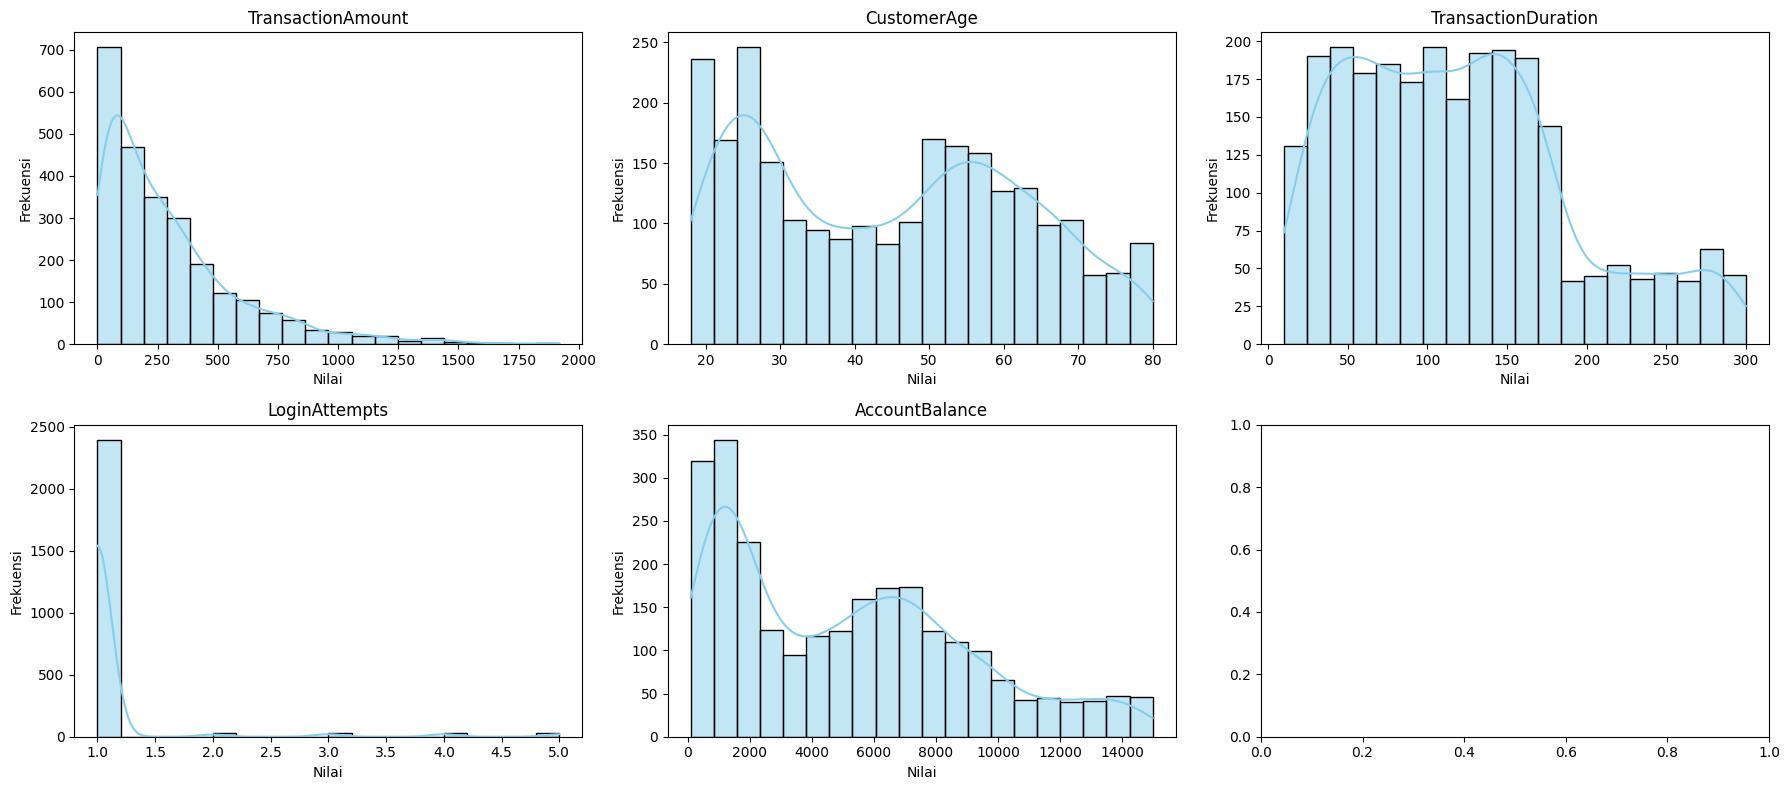

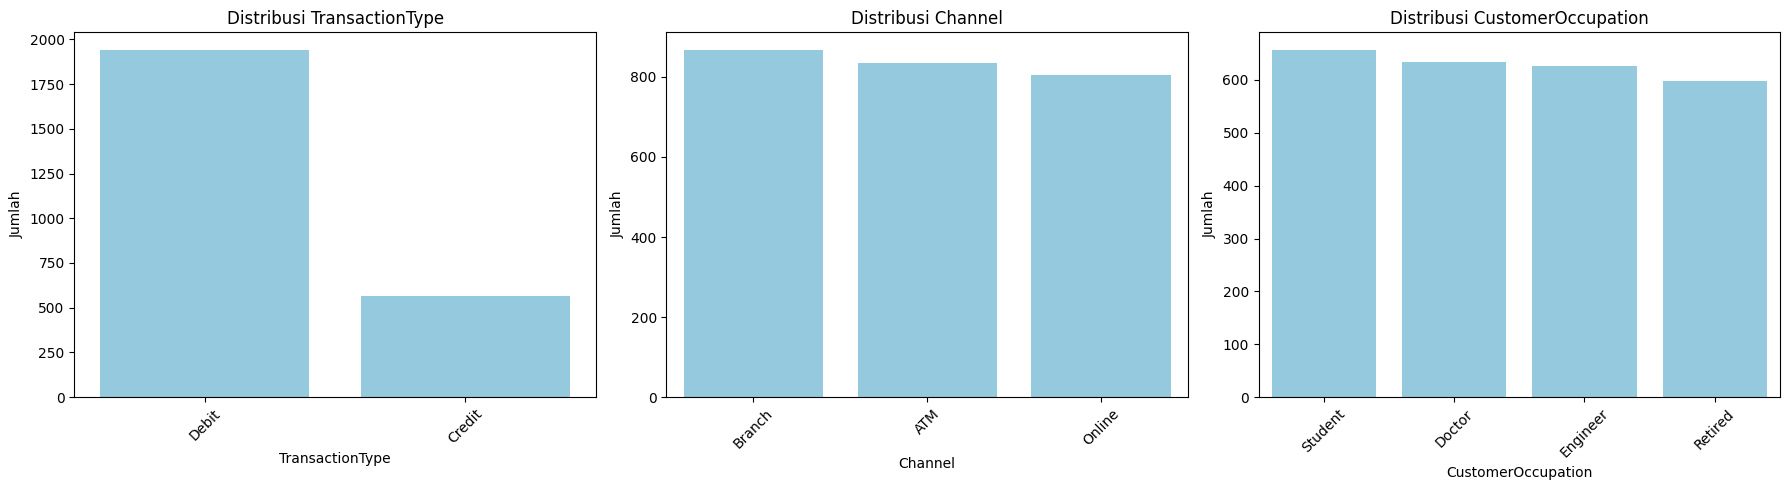

In [7]:
# Histograms of numeric features
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

# Count plots of categorical features
categorical_eda = ['TransactionType', 'Channel', 'CustomerOccupation']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, categorical_eda):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, color='skyblue', ax=ax)
    ax.set_title(f'Distribusi {column}')
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel(column)
    ax.set_ylabel('Jumlah')
plt.tight_layout()
plt.show()

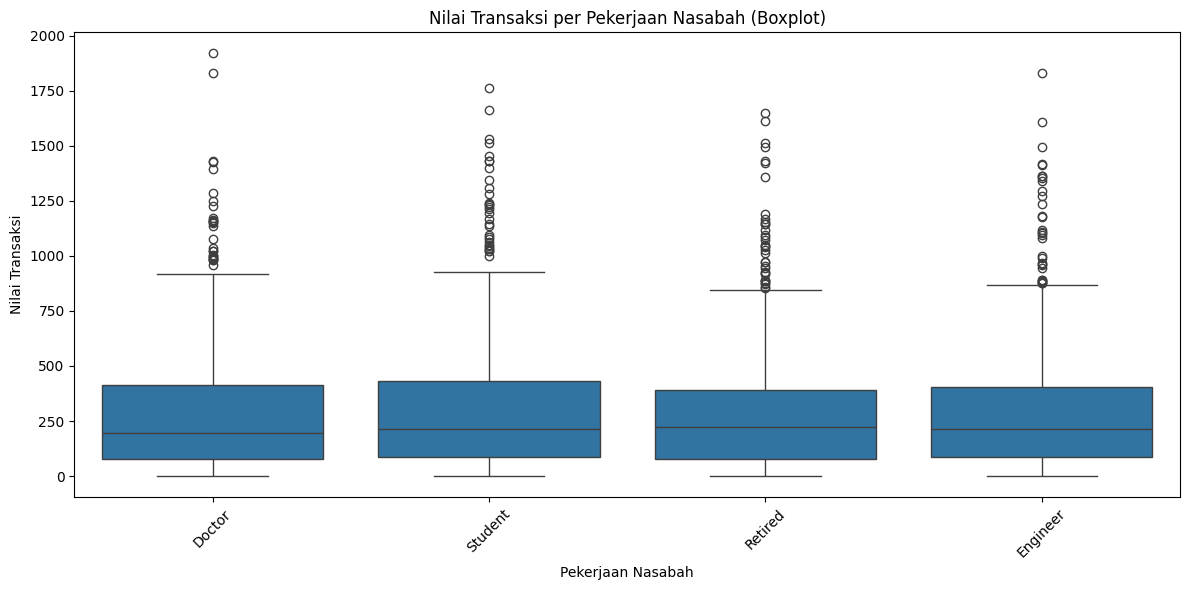

In [8]:
# Boxplot of transaction amount by customer occupation
plt.figure(figsize=(12, 6))
sns.boxplot(x='CustomerOccupation', y='TransactionAmount', data=df)

plt.title('Nilai Transaksi per Pekerjaan Nasabah (Boxplot)')
plt.xlabel('Pekerjaan Nasabah')
plt.ylabel('Nilai Transaksi')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 3. Data Cleaning and Preprocessing

Check for missing values and duplicates, drop them, remove ID, IP address, and date columns, then label-encode the categorical features.

In [9]:
# Count missing values per column
df.isnull().sum()

TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64

In [10]:
# Count duplicated rows
df.duplicated().sum()

np.int64(21)

In [11]:
# Drop rows with missing values
rows_before_missing = len(df)
df.dropna(inplace=True)
rows_after_missing = len(df)
print(f'Jumlah data sebelum dropna: {rows_before_missing}')
print(f'Jumlah data setelah dropna: {rows_after_missing}')

df.isnull().sum()

Jumlah data sebelum dropna: 2537
Jumlah data setelah dropna: 2156


TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64

In [12]:
# Drop duplicate rows
rows_before_duplicate = len(df)
df.drop_duplicates(inplace=True)
rows_after_duplicate = len(df)
print(f'Jumlah data sebelum drop_duplicates: {rows_before_duplicate}')
print(f'Jumlah data setelah drop_duplicates: {rows_after_duplicate}')

df.duplicated().sum()

Jumlah data sebelum drop_duplicates: 2156
Jumlah data setelah drop_duplicates: 2135


np.int64(0)

In [13]:
# Drop ID, IP address, and date columns
cols_to_drop = [col for col in df.columns if
                'id' in col.lower() or
                'ip' in col.lower() or
                'date' in col.lower()]

print('Kolom yang dihapus:', cols_to_drop)

df = df.drop(columns=cols_to_drop)

df.head()

Kolom yang dihapus: ['TransactionID', 'AccountID', 'TransactionDate', 'DeviceID', 'IP Address', 'MerchantID', 'PreviousTransactionDate']


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


In [14]:
# Label-encode categorical features
categorical_cols = list(df.select_dtypes(include=['object']).columns)

encoders = {}

for column in categorical_cols:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


In [15]:
# List the remaining features
df.columns.tolist()

['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

### Outlier handling, scaling, and binning

Remove outliers with the IQR method, standardize the numeric features, and bin customer age into three groups.

In [16]:
# Remove outliers with the IQR method
rows_before_outlier = len(df)

for col in numerical_cols:
    # Quartiles, IQR, and bounds
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep rows within the bounds
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

rows_after_outlier = len(df)
print(f'Jumlah data sebelum outlier handling: {rows_before_outlier}')
print(f'Jumlah data setelah outlier handling: {rows_after_outlier}')
print(f'Jumlah data yang dihapus sebagai outlier: {rows_before_outlier - rows_after_outlier}')

df.describe()

Jumlah data sebelum outlier handling: 2135
Jumlah data setelah outlier handling: 1945
Jumlah data yang dihapus sebagai outlier: 190


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,0.771722,21.299743,0.977378,44.693059,1.503342,119.225193,1.0,5100.811913
std,218.370197,0.419830,12.329250,0.804119,17.743453,1.135888,70.600647,0.0,3907.153333
min,0.260000,0.000000,0.000000,0.000000,18.000000,0.000000,10.000000,1.0,102.200000
25%,78.920000,1.000000,11.000000,0.000000,27.000000,0.000000,63.000000,1.0,1488.650000
50%,199.700000,1.000000,21.000000,1.000000,45.000000,1.000000,111.000000,1.0,4693.600000
75%,374.500000,1.000000,32.000000,2.000000,59.000000,3.000000,162.000000,1.0,7659.990000
max,903.190000,1.000000,42.000000,2.000000,80.000000,3.000000,300.000000,1.0,14977.990000


In [17]:
# Standardize numeric features
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726


In [18]:
# Bin customer age into 3 groups and label-encode the result
col_to_bin = 'CustomerAge'
new_col_name = 'CustomerAge_Bin'
bin_labels = ['Rendah', 'Sedang', 'Tinggi']

df[new_col_name] = pd.qcut(df[col_to_bin], q=3, labels=bin_labels, duplicates='drop')

label_encoder = LabelEncoder()
df[new_col_name] = label_encoder.fit_transform(df[new_col_name])

encoders[new_col_name] = label_encoder
categorical_cols.extend([new_col_name])

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,0
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,0
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,0


## 4. Build the Clustering Model

Choose the number of clusters with the elbow method (silhouette metric), train K-Means, evaluate it with the silhouette score, and visualize the clusters with PCA.

In [19]:
# Copy the preprocessed data used for clustering
df_used = df.copy()

df_used.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,0.983548
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.819475
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


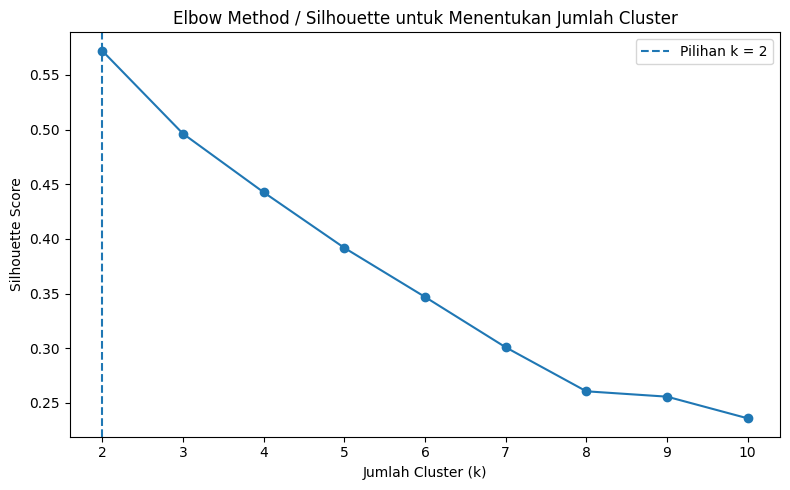

Jumlah cluster yang dipilih berdasarkan Silhouette: 2


In [20]:
# Elbow method with the silhouette metric
model = KMeans()

visualizer = KElbowVisualizer(model, k=(2, 10), metric='silhouette', timings=False)

visualizer.fit(df_used)
visualizer.show()
print('Jumlah cluster yang dipilih berdasarkan Silhouette:', visualizer.elbow_value_)

In [21]:
# Train K-Means with 2 clusters
model = KMeans(n_clusters=2, random_state=42)

model.fit(df_used)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [22]:
# Save the K-Means model
joblib.dump(model, "model_clustering.h5")

['model_clustering.h5']

In [23]:
# Silhouette score of the clustering
labels = model.labels_

score = silhouette_score(df_used, labels)

print("Silhouette Score:", score)

Silhouette Score: 0.572159925838334


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


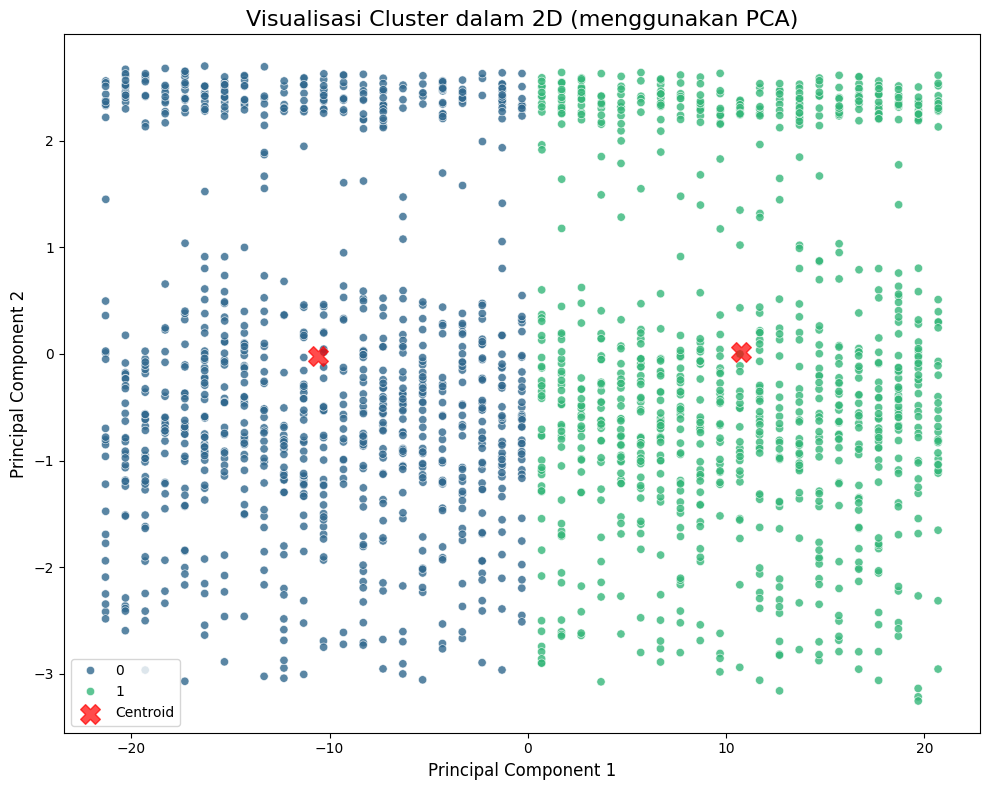

In [24]:
# Visualize the clusters in 2D with PCA
pca = PCA(n_components=2)
df_pca_array = pca.fit_transform(df_used)

df_pca = pd.DataFrame(data=df_pca_array, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Cluster'] = labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette=sns.color_palette("viridis", n_colors=2),
    data=df_pca,
    legend="full",
    alpha=0.8
)

plt.title('Visualisasi Cluster dalam 2D (menggunakan PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)

# Project the centroids onto the PCA plane
centers = pca.transform(model.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Train K-Means on the PCA-reduced data
pca = PCA(n_components=2)
df_pca_array = pca.fit_transform(df_used)

data_final = pd.DataFrame(data=df_pca_array, columns=['PCA1', 'PCA2'])

kmeans_pca = KMeans(n_clusters=2, random_state=42)
kmeans_pca.fit(data_final)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [26]:
# Save the PCA-based K-Means model
joblib.dump(kmeans_pca, "PCA_model_clustering.h5")

['PCA_model_clustering.h5']

## 5. Cluster Interpretation

Summary of each cluster on the standardized numeric features.

In [27]:
# Per-cluster summary of numeric features (scaled values)
df_used['Cluster'] = labels

agg_summary = df_used.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

display(agg_summary)

Cluster                      0     1
TransactionAmount   mean -0.01  0.01
                    min  -1.17 -1.18
                    max   2.96  2.90
CustomerAge         mean  0.02 -0.02
                    min  -1.50 -1.50
                    max   1.99  1.99
TransactionDuration mean  0.03 -0.03
                    min  -1.55 -1.55
                    max   2.56  2.55
LoginAttempts       mean  0.00  0.00
                    min   0.00  0.00
                    max   0.00  0.00
AccountBalance      mean  0.01 -0.01
                    min  -1.28 -1.28
                    max   2.52  2.53

### Interpretation (scaled values)

Based on the aggregation table above, K-Means with k=2 splits the data into Cluster 0 (980 rows) and Cluster 1 (965 rows), so the two clusters are fairly balanced in size. Because every numeric feature went through StandardScaler before clustering, the mean, min, and max values below are standardized values, not the original values. Values close to 0 are close to the overall average of the data.

**Cluster 0:**
- Transaction Amount: mean -0.01 (min -1.17, max 2.96)
- Customer Age: mean 0.02 (min -1.50, max 1.99)
- Transaction Duration: mean 0.03 (min -1.55, max 2.56)
- Login Attempts: mean 0.00 (min 0.00, max 0.00)
- Account Balance: mean 0.01 (min -1.28, max 2.52)

**Cluster 1:**
- Transaction Amount: mean 0.01 (min -1.18, max 2.90)
- Customer Age: mean -0.02 (min -1.50, max 1.99)
- Transaction Duration: mean -0.03 (min -1.55, max 2.55)
- Login Attempts: mean 0.00 (min 0.00, max 0.00)
- Account Balance: mean -0.01 (min -1.28, max 2.53)

Judging by the means, Cluster 0 is slightly higher on Customer Age, Transaction Duration, and Account Balance, while Cluster 1 is slightly higher on Transaction Amount. The differences in means across these five features are small (about 0.01 to 0.03), so none of the five numeric features drives the separation between the two clusters on its own. Login Attempts in particular is constant at 0.00 in both clusters because, after outlier removal, almost all remaining rows have the same number of login attempts, so this feature practically does not distinguish one cluster from the other. The cluster number is only a group label, so Cluster 0 does not mean better or higher than Cluster 1.

## 6. Export Data

Rename the cluster column to `Target` and save the clustered data to CSV.

In [28]:
# Rename the cluster column to Target
df_used.rename(columns={"Cluster": "Target"}, inplace=True)

df_used.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,0,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,0,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,0,1


In [29]:
# Save the clustered data
df_used.to_csv('data_clustering.csv', index=False)

## 7. Inverse Transform and Interpretation

Return numeric features to their original scale and categorical features to their original categories, then summarize each cluster again.

In [30]:
# Inverse-transform numeric features to their original scale
df_inverse = df_used.copy()

df_inverse[numerical_cols] = scaler.inverse_transform(df_inverse[numerical_cols])

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin,Target
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,2,1
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,2,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,0,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,0,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,0,1


In [31]:
# Inverse-transform encoded features to their original categories
for column in categorical_cols:
    encoder = encoders[column]
    df_inverse[column] = encoder.inverse_transform(df_inverse[column].astype(int))

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Tinggi,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Tinggi,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Rendah,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Rendah,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Rendah,1


In [32]:
# Per-cluster summary on original values: numeric (mean, min, max) and categorical (mode)
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).T

display(agg_summary_num)
display(agg_summary_cat)

Target                           0         1
TransactionAmount   mean    255.55    258.15
                    min       0.32      0.26
                    max     903.19    889.01
CustomerAge         mean     45.06     44.33
                    min      18.00     18.00
                    max      80.00     80.00
TransactionDuration mean    121.12    117.30
                    min      10.00     10.00
                    max     300.00    299.00
LoginAttempts       mean      1.00      1.00
                    min       1.00      1.00
                    max       1.00      1.00
AccountBalance      mean   5142.17   5058.81
                    min     117.98    102.20
                    max   14942.78  14977.99

Target,0,1
TransactionType,Debit,Debit
Location,Charlotte,Tucson
Channel,Branch,Branch
CustomerOccupation,Doctor,Student
CustomerAge_Bin,Sedang,Rendah


### Interpretation (original values)

After the inverse transform, numeric features are back in their original units (no longer standardized) and categorical features are back to their original categories, so the characteristics of each cluster are easier to understand than in the scaled form.

**Cluster 0 (980 rows):**
- Transaction Amount: mean 255.55 (min 0.32, max 903.19)
- Customer Age: mean 45.06 years (min 18, max 80 years)
- Transaction Duration: mean 121.12 seconds (min 10, max 300 seconds)
- Login Attempts: mean 1.00 (min 1, max 1)
- Account Balance: mean 5142.17 (min 117.98, max 14942.78)
- Mode of Transaction Type: Debit
- Mode of Location: Charlotte
- Mode of Channel: Branch
- Mode of Customer Occupation: Doctor
- Mode of Customer Age Bin: Sedang (medium)

**Cluster 1 (965 rows):**
- Transaction Amount: mean 258.15 (min 0.26, max 889.01)
- Customer Age: mean 44.33 years (min 18, max 80 years)
- Transaction Duration: mean 117.30 seconds (min 10, max 299 seconds)
- Login Attempts: mean 1.00 (min 1, max 1)
- Account Balance: mean 5058.81 (min 102.20, max 14977.99)
- Mode of Transaction Type: Debit
- Mode of Location: Tucson
- Mode of Channel: Branch
- Mode of Customer Occupation: Student
- Mode of Customer Age Bin: Rendah (low)

**Analysis:** Once returned to their original units, Transaction Amount, Customer Age, Transaction Duration, and Account Balance turn out not to differ much between the two clusters (the differences in means are relatively small), and Login Attempts is constant at 1 in both. The most visible differences come from the categorical features: Cluster 0 is dominated by customers with the occupation Doctor, the location Charlotte, and the medium Customer Age Bin, while Cluster 1 is dominated by customers with the occupation Student, the location Tucson, and the low Customer Age Bin. So the separation between the two clusters is influenced more by the combination of customer profession and age group than by transaction values or account balances.

> **Note (added during review):** Checking the exported data shows that a single threshold on the label-encoded `Location` column reproduces the cluster labels exactly: the two clusters share no city (22 cities in Cluster 0 and 21 in Cluster 1). The other features (occupation, age bin, channel, transaction type, and the numeric columns) are spread almost evenly across both clusters, so the modes listed above come from near-uniform distributions and do not characterize the clusters. Categorical features were label-encoded but not scaled, so the larger numeric range of the `Location` codes dominates the K-Means distance.

### Check and export the inverse-transformed data

In [33]:
# Check the inverse-transformed data
df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,CustomerAge_Bin,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Tinggi,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Tinggi,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Rendah,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Rendah,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Rendah,1


In [34]:
# Save the inverse-transformed data
df_inverse.to_csv('data_clustering_inverse.csv', index=False)